# ICC Men's T20 World Cup: Ball-by-Ball Exploratory Data Analysis

## Project Overview
This project explores ball-by-ball delivery data from ICC Men's T20 World Cup matches using Python, Pandas, Matplotlib, and Seaborn. It examines scoring by match phase, over-by-over scoring, batter strike rate and dot-ball percentage, dismissal modes, and selected numerical relationships.

### Objectives
1. Inspect the dataset and apply clearly justified missing-value treatment.
2. Create over numbers, match phases, legal-ball indicators, and delivery outcomes.
3. Compare phase-wise run rate, dot-ball percentage, and boundary percentage using explicit denominators.
4. Calculate average runs per over per innings that reached that over.
5. Compare batter strike rate and dot-ball percentage using a minimum balls-faced threshold.
6. Summarize dismissal modes and inspect selected numerical correlations.

**Data note:** The dataset is downloaded from Cricsheet. Results describe the available tournament data and should not be interpreted as causal conclusions.


In [11]:
# NumPy: Used for fast numerical operations and arrays
import numpy as np

# Pandas: The core tool for loading, cleaning, grouping, and manipulating tabular data
import pandas as pd

# Matplotlib & Seaborn: Used for building statistical data visualisations
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visual defaults for all plots
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

In [12]:
import os
import urllib.request
import zipfile
import pandas as pd

# Download Cricsheet's ICC Men's T20 World Cup ball-by-ball dataset.
url = "https://cricsheet.org/downloads/icc_mens_t20_world_cup_csv2.zip"
zip_path = "t20_world_cup.zip"
data_dir = "t20_wc_data"
os.makedirs(data_dir, exist_ok=True)
urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(data_dir)

# Load the consolidated delivery file.
df = pd.read_csv(os.path.join(data_dir, "all_matches.csv"))
print(f"Dataset: {df.shape[0]:,} delivery records across {df.shape[1]} columns")
df.head()


Dataset: 52,521 delivery records across 27 columns


,match_id,season,start_date,venue,innings,ball,actual_delivery,batting_team,bowling_team,striker,...,legbyes,penalty,non_boundary,wicket_type,player_dismissed,other_wicket_type,other_player_dismissed,fielder_1,fielder_2,fielder_3
0,1273712,2021/22,2021-10-17,Al Amerat Cricket Ground Oman Cricket (Ministr...,1,0.1,0.1,Papua New Guinea,Oman,TP Ura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1273712,2021/22,2021-10-17,Al Amerat Cricket Ground Oman Cricket (Ministr...,1,0.2,0.2,Papua New Guinea,Oman,TP Ura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1273712,2021/22,2021-10-17,Al Amerat Cricket Ground Oman Cricket (Ministr...,1,0.3,0.3,Papua New Guinea,Oman,TP Ura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1273712,2021/22,2021-10-17,Al Amerat Cricket Ground Oman Cricket (Ministr...,1,0.4,0.4,Papua New Guinea,Oman,TP Ura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1273712,2021/22,2021-10-17,Al Amerat Cricket Ground Oman Cricket (Ministr...,1,0.5,0.5,Papua New Guinea,Oman,TP Ura,...,NaN,NaN,NaN,bowled,TP Ura,NaN,NaN,NaN,NaN,NaN


## 1. Data Health Check & Missing Values

Missing values need to be interpreted according to the meaning of each field. Missing extra-run fields commonly mean zero runs of that extra type, while missing fielder or dismissal details may simply mean that no such event occurred. We fill only the extra-run fields where missing means zero and keep other missing values unless a specific rule justifies changing them.


In [13]:
# Standardize column names.
df.columns = df.columns.str.strip().str.replace(' ', '_').str.lower()

print('Columns with missing values before treatment:')
missing_before = df.isna().sum()
print(missing_before[missing_before > 0].sort_values(ascending=False))

# Missing values in these extra-run fields represent zero of that extra type.
extras_cols = ['wides', 'noballs', 'byes', 'legbyes', 'penalty']
for col in extras_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# Keep a readable label for deliveries without a primary dismissal type.
df['wicket_type'] = df['wicket_type'].fillna('None')

# A dismissal can be recorded in either primary or secondary dismissal fields.
df['is_wicket'] = (
    df['player_dismissed'].notna() | df['other_player_dismissed'].notna()
).astype(int)

print(f"\nExact duplicate rows: {df.duplicated().sum():,}")
print(f"Rows with a dismissal recorded: {df['is_wicket'].sum():,}")


Columns with missing values before treatment:
other_wicket_type         52521
other_player_dismissed    52521
fielder_3                 52521
penalty                   52517
non_boundary              52513
fielder_2                 52402
byes                      52367
noballs                   52313
legbyes                   51676
wides                     50818
fielder_1                 50469
player_dismissed          49620
wicket_type               49620
dtype: int64

Exact duplicate rows: 0
Rows with a dismissal recorded: 2,901


## 2. Feature Engineering: Match Phases & Delivery Outcomes

We create an over number from the over.ball notation, calculate total runs, and distinguish **legal balls** from **balls faced**. These are not interchangeable: wides do not count as balls faced, while no-balls generally do count as balls faced but do not count as legal balls in the over.

The phase definitions are Powerplay (overs 1–6), Middle Overs (7–15), and Death Overs (16–20). For the standard 20-over analysis, subsequent summaries use innings 1 and 2 and overs 1–20, excluding any Super Over innings.


In [14]:
# Convert over.ball notation to an over number (e.g. 0.1 -> over 1; 19.6 -> over 20).
df['over_number'] = df['ball'].astype(str).str.split('.').str[0].astype(int) + 1

# Cricsheet's `extras` column is the total extras conceded on that delivery.
df['total_runs'] = df['runs_off_bat'].fillna(0) + df['extras'].fillna(0)

# Cricket-specific indicators.
df['is_legal_ball'] = df['wides'].eq(0) & df['noballs'].eq(0)
# A wide is not counted as a ball faced; a no-ball is generally counted as faced.
df['is_ball_faced'] = df['wides'].eq(0)
# A dot ball is a legal delivery on which no runs were scored, including a wicket delivery.
df['is_dot_ball'] = df['is_legal_ball'] & df['total_runs'].eq(0)
# For a consistent phase metric, boundary percentage below counts boundaries on legal balls.
df['is_boundary'] = df['is_legal_ball'] & df['runs_off_bat'].isin([4, 6])

phase_order = ['Powerplay (1-6)', 'Middle Overs (7-15)', 'Death Overs (16-20)']
def get_match_phase(over):
    if over <= 6:
        return 'Powerplay (1-6)'
    elif over <= 15:
        return 'Middle Overs (7-15)'
    return 'Death Overs (16-20)'

df['match_phase'] = pd.Categorical(
    df['over_number'].apply(get_match_phase),
    categories=phase_order,
    ordered=True
)

# Mutually exclusive labels for charting delivery outcomes. Independent metric columns
# above are used for the statistical calculations so that a wicket does not hide a dot ball.
def categorize_delivery(row):
    if row['is_wicket'] == 1:
        return 'Wicket'
    if row['runs_off_bat'] == 4:
        return 'Four'
    if row['runs_off_bat'] == 6:
        return 'Six'
    if row['is_dot_ball']:
        return 'Dot Ball'
    if row['runs_off_bat'] == 0 and row['total_runs'] > 0:
        return 'Extras-only scoring'
    if 1 <= row['runs_off_bat'] <= 3:
        return 'Runs off bat (1-3)'
    return 'Other scoring delivery'

df['ball_outcome'] = df.apply(categorize_delivery, axis=1)

# Standard regulation innings only; excludes Super Overs if they are present in the source.
analysis_df = df[
    df['innings'].isin([1, 2]) & df['over_number'].between(1, 20)
].copy()

print('Delivery outcome distribution (all loaded innings):')
print(df['ball_outcome'].value_counts(dropna=False))
print(f"\nRegulation delivery records used for the 20-over analyses: {len(analysis_df):,}")


Delivery outcome distribution (all loaded innings):
ball_outcome
Runs off bat (1-3)        22564
Dot Ball                  16661
Four                       5253
Wicket                     2901
Extras-only scoring        2783
Six                        2352
Other scoring delivery        7
Name: count, dtype: int64

Regulation delivery records used for the 20-over analyses: 52,492


## 3. Phase Scoring Rate, Dot-Ball Pressure & Boundaries

Run rate is calculated as total runs divided by **legal overs** (legal balls ÷ 6). Dot-ball percentage and boundary percentage use legal balls as their denominator. These definitions are explicit so the metrics are comparable and are not inflated or diluted by wides and no-balls.


Phase performance summary (regulation innings only):
        match_phase  legal_balls  total_runs  run_rate  dot_ball_pct  boundary_pct
    Powerplay (1-6)        16437       20001      7.30         49.51         17.19
Middle Overs (7-15)        23498       28994      7.40         33.80         12.04
Death Overs (16-20)        10651       16371      9.22         31.85         17.85


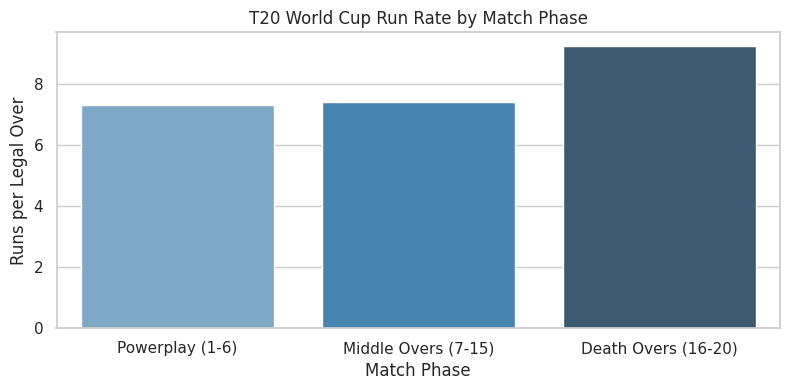

In [15]:
phase_summary = (
    analysis_df.groupby('match_phase', observed=False)
    .agg(
        delivery_records=('ball', 'count'),
        legal_balls=('is_legal_ball', 'sum'),
        total_runs=('total_runs', 'sum'),
        wicket_deliveries=('is_wicket', 'sum'),
        dots=('is_dot_ball', 'sum'),
        boundaries=('is_boundary', 'sum'),
    )
    .reset_index()
)

phase_summary['run_rate'] = (
    phase_summary['total_runs'] * 6 / phase_summary['legal_balls'].replace(0, np.nan)
).round(2)
phase_summary['dot_ball_pct'] = (
    phase_summary['dots'] / phase_summary['legal_balls'].replace(0, np.nan) * 100
).round(2)
phase_summary['boundary_pct'] = (
    phase_summary['boundaries'] / phase_summary['legal_balls'].replace(0, np.nan) * 100
).round(2)

print('Phase performance summary (regulation innings only):')
display_cols = ['match_phase', 'legal_balls', 'total_runs', 'run_rate', 'dot_ball_pct', 'boundary_pct']
print(phase_summary[display_cols].to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(
    data=phase_summary,
    x='match_phase',
    y='run_rate',
    hue='match_phase',
    order=phase_order,
    hue_order=phase_order,
    palette='Blues_d',
    legend=False
)
plt.title('T20 World Cup Run Rate by Match Phase')
plt.xlabel('Match Phase')
plt.ylabel('Runs per Legal Over')
plt.tight_layout()
plt.show()


## 4. Over-by-Over Scoring Profile (Overs 1–20)

The average for each over is calculated across **innings that actually reached that over**, rather than dividing both innings' runs by the number of matches. This avoids doubling the denominator mismatch between deliveries from two innings and unique match IDs.


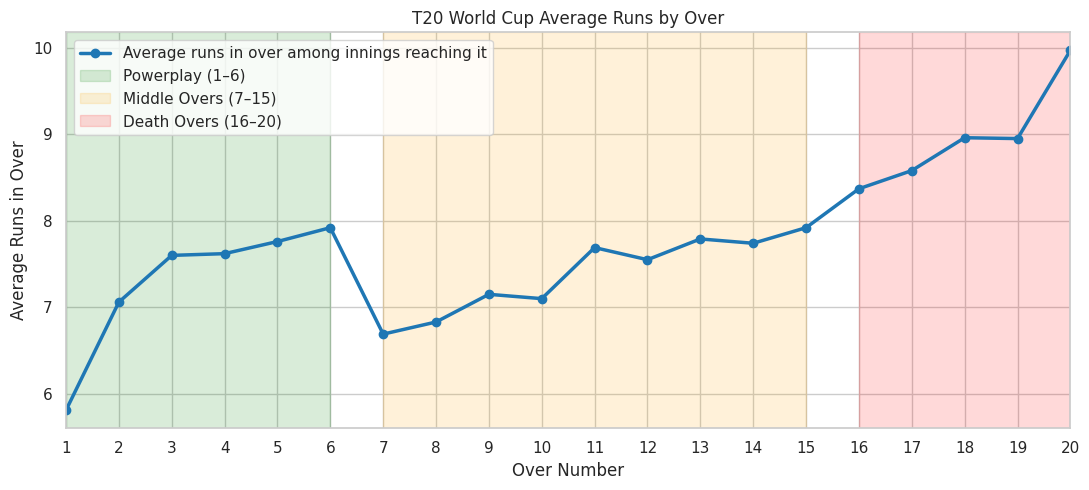

In [16]:
# First aggregate within each match innings and over, then average across innings that reached it.
over_innings = (
    analysis_df.groupby(['match_id', 'innings', 'over_number'], as_index=False)
    .agg(
        runs_in_over=('total_runs', 'sum'),
        legal_balls=('is_legal_ball', 'sum')
    )
)

over_stats = (
    over_innings.groupby('over_number', as_index=False)
    .agg(
        total_runs=('runs_in_over', 'sum'),
        innings_count=('innings', 'size')
    )
)
over_stats['runs_per_over'] = (
    over_stats['total_runs'] / over_stats['innings_count']
).round(2)

plt.figure(figsize=(11, 5))
plt.plot(
    over_stats['over_number'],
    over_stats['runs_per_over'],
    marker='o',
    linewidth=2.5,
    label='Average runs in over among innings reaching it'
)
plt.axvspan(1, 6, alpha=0.15, color='green', label='Powerplay (1–6)')
plt.axvspan(7, 15, alpha=0.15, color='orange', label='Middle Overs (7–15)')
plt.axvspan(16, 20, alpha=0.15, color='red', label='Death Overs (16–20)')
plt.title('T20 World Cup Average Runs by Over')
plt.xlabel('Over Number')
plt.ylabel('Average Runs in Over')
plt.xticks(range(1, 21))
plt.xlim(1, 20)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


## 5. Batter Efficiency: Strike Rate vs. Dot-Ball Percentage

Strike rate uses batter runs off the bat divided by balls faced. **Balls faced exclude wides, but no-balls generally count as balls faced**; this is different from legal balls used for run rate. Dot-ball percentage is the share of balls faced that were legal, zero-run deliveries. Batters are included only if they faced at least 120 balls in the regulation innings covered by this dataset.


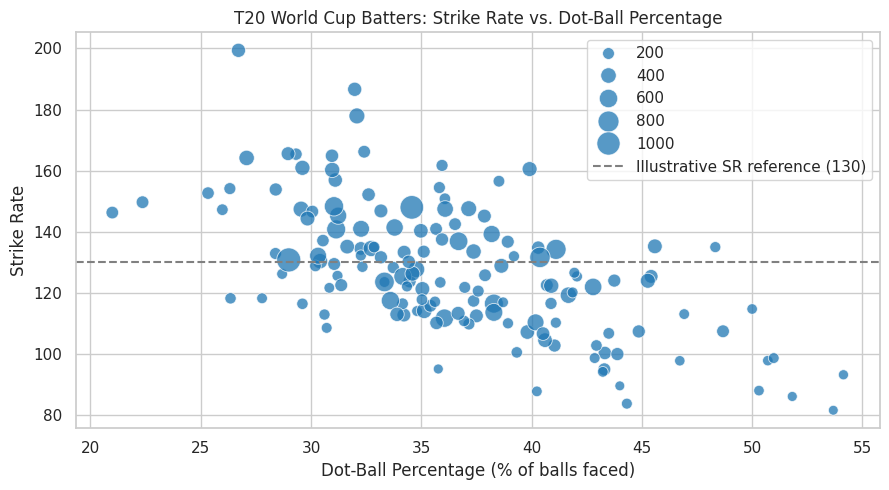

In [17]:
batter_stats = (
    analysis_df.groupby('striker')
    .agg(
        balls_faced=('is_ball_faced', 'sum'),
        runs_scored=('runs_off_bat', 'sum'),
        dots=('is_dot_ball', 'sum'),
    )
    .reset_index()
)

qualified_batters = batter_stats[batter_stats['balls_faced'] >= 120].copy()
qualified_batters['strike_rate'] = (
    qualified_batters['runs_scored'] / qualified_batters['balls_faced'] * 100
).round(2)
qualified_batters['dot_pct'] = (
    qualified_batters['dots'] / qualified_batters['balls_faced'] * 100
).round(2)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=qualified_batters,
    x='dot_pct',
    y='strike_rate',
    size='runs_scored',
    sizes=(50, 300),
    alpha=0.75,
)
plt.axhline(130, linestyle='--', color='grey', label='Illustrative SR reference (130)')
plt.title('T20 World Cup Batters: Strike Rate vs. Dot-Ball Percentage')
plt.xlabel('Dot-Ball Percentage (% of balls faced)')
plt.ylabel('Strike Rate')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 6. Modes of Dismissal

This section counts dismissal types recorded in the primary and secondary dismissal fields. It describes the frequency of dismissal modes; it does **not** calculate a dismissal hazard rate, which would require a defined exposure denominator and a more specific statistical method.


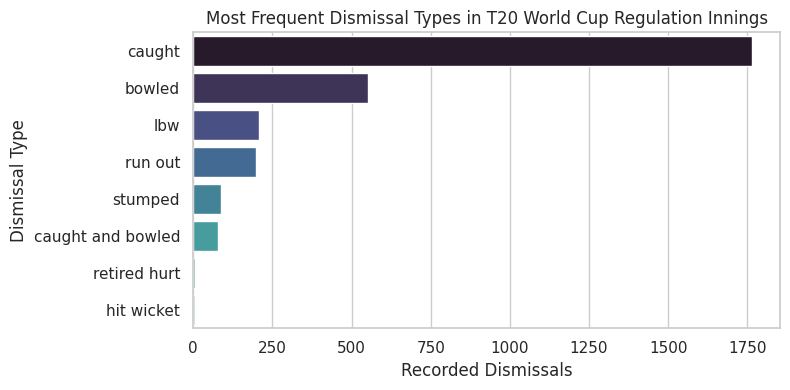

In [18]:
# Count primary and secondary dismissal types, where present.
primary_dismissals = analysis_df.loc[
    analysis_df['wicket_type'].ne('None'), 'wicket_type'
].dropna()
secondary_dismissals = analysis_df['other_wicket_type'].dropna()
dismissal_types = pd.concat([primary_dismissals, secondary_dismissals], ignore_index=True)
top_dismissals = dismissal_types.value_counts().head(8)

if not top_dismissals.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(
        x=top_dismissals.values,
        y=top_dismissals.index,
        hue=top_dismissals.index,
        palette='mako',
        legend=False
    )
    plt.title('Most Frequent Dismissal Types in T20 World Cup Regulation Innings')
    plt.xlabel('Recorded Dismissals')
    plt.ylabel('Dismissal Type')
    plt.tight_layout()
    plt.show()
else:
    print('No dismissal types were available to plot.')


## 7. Selected Numerical Correlations

The heatmap uses selected delivery variables rather than every numeric column. Identifier fields such as `match_id` are excluded because correlations with IDs are not meaningful. Note that `total_runs` is derived from `runs_off_bat + extras`, so correlations involving these fields are partly mathematical relationships and should not be interpreted as independent or causal discoveries.


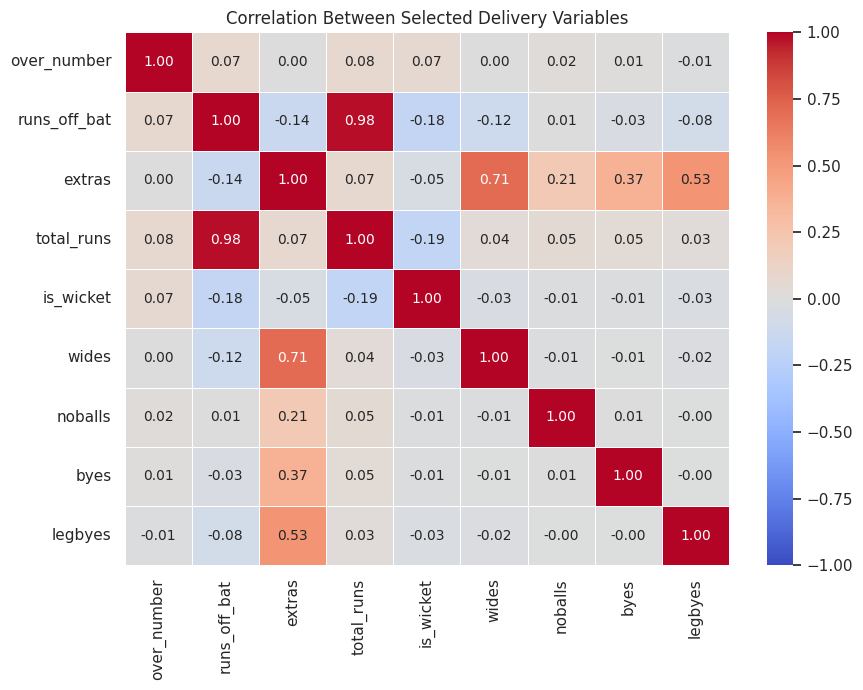

In [19]:
corr_cols = [
    'over_number',
    'runs_off_bat',
    'extras',
    'total_runs',
    'is_wicket',
    'wides',
    'noballs',
    'byes',
    'legbyes',
]
corr_matrix = analysis_df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    linewidths=0.5,
)
plt.title('Correlation Between Selected Delivery Variables')
plt.tight_layout()
plt.show()


## 8. Key Findings

The code cell below generates a few descriptive findings directly from the refreshed tables. Re-run the entire notebook after downloading the current dataset; do not reuse numeric findings from an older notebook run. These are descriptive summaries, not evidence that a particular match phase or delivery feature causes a scoring outcome.


In [20]:
# Generate findings from the current run so the text cannot silently retain stale values.
if not phase_summary.empty:
    fastest_phase = phase_summary.loc[phase_summary['run_rate'].idxmax()]
    highest_dot_phase = phase_summary.loc[phase_summary['dot_ball_pct'].idxmax()]
    print(f"Highest phase run rate: {fastest_phase['match_phase']} ({fastest_phase['run_rate']:.2f} runs per legal over).")
    print(f"Highest dot-ball percentage: {highest_dot_phase['match_phase']} ({highest_dot_phase['dot_ball_pct']:.2f}% of legal balls).")
if not over_stats.empty:
    peak_over = over_stats.loc[over_stats['runs_per_over'].idxmax()]
    print(f"Highest average runs in an over: over {int(peak_over['over_number'])} ({peak_over['runs_per_over']:.2f} runs; {int(peak_over['innings_count'])} innings reached this over).")
if not top_dismissals.empty:
    print(f"Most frequent recorded dismissal type: {top_dismissals.index[0]} ({int(top_dismissals.iloc[0])} records).")
print('Interpret these as aggregate descriptions of the included regulation innings, not causal effects.')


Highest phase run rate: Death Overs (16-20) (9.22 runs per legal over).
Highest dot-ball percentage: Powerplay (1-6) (49.51% of legal balls).
Highest average runs in an over: over 20 (9.97 runs; 306 innings reached this over).
Most frequent recorded dismissal type: caught (1765 records).
Interpret these as aggregate descriptions of the included regulation innings, not causal effects.


## 9. Conclusion

This exploratory analysis examines scoring patterns across match phases and overs, compares batter strike rate with dot-ball percentage, summarizes dismissal modes, and explores selected relationships between delivery variables. The calculations explicitly distinguish legal balls from balls faced and exclude Super Over innings from the standard 20-over summaries. The results can motivate further questions, but they do not establish causal effects or predict future match outcomes.


## 10. Limitations

- **Tournament scope:** The analysis is limited to ICC Men's T20 World Cup matches present in the downloaded Cricsheet dataset; it should not automatically be generalized to franchise leagues or all T20 cricket.
- **Contextual factors:** The delivery records do not fully quantify pitch conditions, boundary dimensions, weather, dew, team strategy, or match situation.
- **Different opposition strengths:** Matches between teams with different levels of experience can influence aggregate scoring patterns.
- **Descriptive analysis:** Correlations and group summaries do not prove causation. Some fields, such as `total_runs`, are derived from other columns.
- **Batter sample threshold:** Requiring at least 120 balls faced makes the batter comparison less sensitive to very small samples, but excludes many players and may favor players in teams that played more matches.
- **Denominator choices:** Phase run rate uses legal balls; batter strike rate uses balls faced; the notebook states these definitions explicitly because they are not interchangeable.
- **Data refresh:** The notebook downloads the current dataset when run. Rerun all cells before publishing numeric findings so saved results match the current source data.
